# The Elizabeth line's effect on station traffic, from daily data

The extended analysis estimated the Elizabeth line's effect from **annual** counts: the four new
central stations grew about 84% more than nearby stations between 2019 and 2023. This notebook
re-estimates it from **daily** station footfall (TfL Network Demand, entry + exit taps, 2019-2026),
which shows *when* the effect appeared and how it built up.

**Design: event study (difference-in-differences by week).**

* **Treated:** Farringdon, Tottenham Court Road, Whitechapel (opened 24 May 2022) and Bond Street
  (opened 24 Oct 2022), as in the annual analysis.
* **Control:** the other Underground stations within 4 km of them, as in the annual analysis.
  Paddington, Liverpool Street, Canary Wharf, Stratford and Ealing Broadway are left out. So are the
  stations of the **Northern line Bank branch from Kennington to Angel**: the line was closed between
  Kennington and Moorgate from 15 January to 16 May 2022 (Borough station closed), exactly the baseline
  before the opening, so their traffic jumped back afterwards for reasons unrelated to the Elizabeth line.
  The annual analysis (2019 vs 2023) was not affected by that closure.
* **Data:** weekdays only; bank holidays, strikes and other atypical days removed
  (`tfl_bus.atypical_days`); Underground gate series only, as in the annual counts.
* **Estimator:** for each station, log daily footfall minus its mean over the 16 weeks before the
  opening; the effect on a day is the treated stations' mean minus the control stations' mean; days are
  averaged by week since opening. Weeks before opening test whether the groups moved together.
* **Inference:** with only four treated stations, standard errors are unreliable, so an exact placebo
  (permutation) test re-runs the estimate with every possible choice of control stations as "treated".

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import tfl_analysis as T
import tfl_bus as B

B.RESULTS.mkdir(parents=True, exist_ok=True)

OPEN = {'Farringdon': '2022-05-24', 'Tottenham Court Road': '2022-05-24',
        'Whitechapel': '2022-05-24', 'Bond Street': '2022-10-24'}
CENTRAL, BOND = ['Farringdon', 'Tottenham Court Road', 'Whitechapel'], ['Bond Street']
MILESTONES = {'through services': '2022-11-06', 'full timetable': '2023-05-21'}
BANK_BRANCH_2022 = {'Kennington', 'Elephant & Castle', 'Borough', 'London Bridge', 'Bank and Monument',
                    'Moorgate', 'Old Street', 'Angel'}   # Kennington-Moorgate closed 15 Jan - 16 May 2022
EXCLUDED = set(OPEN) | {'Paddington', 'Liverpool Street', 'Canary Wharf', 'Stratford', 'Ealing Broadway'} | BANK_BRANCH_2022
PRE_WEEKS, MAX_WEEK = 16, 156

panel = B.footfall_panel()                 # weekday LU entries+exits, atypical days removed
logp = np.log(panel.where(panel > 0))      # zero counts (station closed) become missing

pos = T.positions_2024()
centre = np.mean([pos[s] for s in OPEN], axis=0)
dist_centre = pd.Series({s: B.haversine_m(pos[s][1], pos[s][0], centre[1], centre[0]) for s in panel.columns})
dist_treated = pd.Series({s: min(B.haversine_m(pos[s][1], pos[s][0], pos[t][1], pos[t][0]) for t in OPEN)
                          for s in panel.columns})
CONTROL = [s for s in panel.columns if s not in EXCLUDED and dist_centre[s] <= 4000]
ALL_LU = [s for s in panel.columns if s not in EXCLUDED]
print(f"{len(panel):,} weekdays, {panel.shape[1]} Underground stations; {len(CONTROL)} central controls")
print('excluded Bank-branch stations within 4 km:', sorted(s for s in BANK_BRANCH_2022 if s in panel and dist_centre[s] <= 4000))

1,930 weekdays, 267 Underground stations; 48 central controls
excluded Bank-branch stations within 4 km: ['Angel', 'Bank and Monument', 'Borough', 'Elephant & Castle', 'Kennington', 'London Bridge', 'Moorgate', 'Old Street']


In [2]:
def deviations(date, pre_weeks=PRE_WEEKS, baseline=None):
    '''log footfall minus each station's mean over the baseline period
    (default: the pre_weeks before `date`).'''
    E = pd.Timestamp(date)
    lo, hi = baseline or (E - pd.Timedelta(weeks=pre_weeks), E - pd.Timedelta(days=1))
    return logp - logp.loc[lo:hi].mean()

def weekly(date, **kw):
    '''Station x week-since-`date` table of mean deviations (weeks -PRE_WEEKS..MAX_WEEK).'''
    dev = deviations(date, **kw)
    week = (dev.index - pd.Timestamp(date)).days // 7
    return dev.groupby(week).mean().loc[-PRE_WEEKS:MAX_WEEK]

def event_study(treated, date, control=CONTROL, **kw):
    '''Weekly effect (log points) of treated vs control stations, by week since `date`.'''
    W = weekly(date, **kw)
    return W[treated].mean(axis=1) - W[control].mean(axis=1)

pct = lambda x: 100 * (np.exp(x) - 1)
es_central = event_study(CENTRAL, OPEN['Farringdon'])
es_bond = event_study(BOND, OPEN['Bond Street'])

### Placebo test

Take every possible set of control stations of the same size, pretend they opened on the same date,
and estimate the same event study against the remaining controls. This gives the full range of
"effects" that arise by chance among comparable stations. With one treated station (Bond Street)
there are only as many placebos as controls, so the smallest possible p-value is 1 / (controls + 1).

In [3]:
def placebo(n_treated, date):
    '''Exact permutation: every set of n_treated control stations as placebo treated.'''
    W = weekly(date)[CONTROL]
    X = W.apply(lambda c: c.fillna(W.mean(axis=1))).values     # a week with no data: use the control mean
    n = X.shape[1]
    combos = np.array(list(itertools.combinations(range(n), n_treated)))
    pick_sum = X[:, combos].sum(axis=2)                        # weeks x combos
    gap = pick_sum / n_treated - (X.sum(axis=1)[:, None] - pick_sum) / (n - n_treated)
    return pd.DataFrame(gap.T, columns=W.index)

plc_central = placebo(len(CENTRAL), OPEN['Farringdon'])
plc_bond = placebo(1, OPEN['Bond Street'])
pd.DataFrame({'central three': pct(es_central), 'central placebo 2.5%': pct(plc_central.quantile(.025)),
              'central placebo 97.5%': pct(plc_central.quantile(.975)), 'Bond Street': pct(es_bond),
              'Bond Street placebo 2.5%': pct(plc_bond.quantile(.025)),
              'Bond Street placebo 97.5%': pct(plc_bond.quantile(.975))}).round(2).to_csv(
    B.RESULTS / 'elizabeth_line_daily_weekly.csv', index_label='weeks since opening')
print(f"placebo sets: {len(plc_central):,} for the central three, {len(plc_bond)} for Bond Street")

placebo sets: 17,296 for the central three, 48 for Bond Street


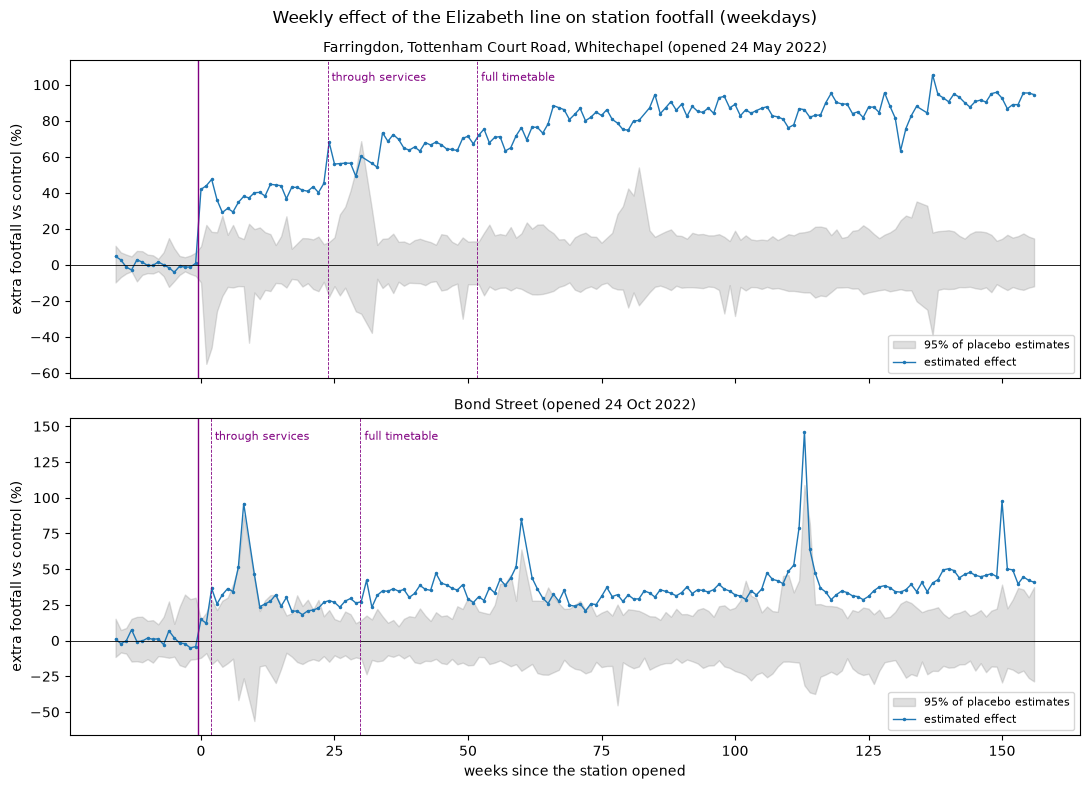

In [4]:
fig, axs = plt.subplots(2, 1, figsize=(11, 8), sharex=True)
for ax, es, plc, title, date in [
        (axs[0], es_central, plc_central, 'Farringdon, Tottenham Court Road, Whitechapel (opened 24 May 2022)', OPEN['Farringdon']),
        (axs[1], es_bond, plc_bond, 'Bond Street (opened 24 Oct 2022)', OPEN['Bond Street'])]:
    lo, hi = plc.quantile(.025), plc.quantile(.975)
    ax.fill_between(lo.index, pct(lo), pct(hi), color='grey', alpha=.25, label='95% of placebo estimates')
    ax.plot(es.index, pct(es), 'C0.-', ms=3, lw=1, label='estimated effect')
    ax.axvline(-.5, color='purple', lw=1); ax.axhline(0, color='black', lw=.6)
    for name, d in MILESTONES.items():
        w = (pd.Timestamp(d) - pd.Timestamp(date)).days / 7
        if w > 0:
            ax.axvline(w, color='purple', lw=.6, ls='--'); ax.text(w, ax.get_ylim()[1] * .9, ' ' + name, fontsize=8, color='purple')
    ax.set_title(title, fontsize=10); ax.set_ylabel('extra footfall vs control (%)'); ax.legend(loc='lower right', fontsize=8)
axs[1].set_xlabel('weeks since the station opened')
plt.suptitle('Weekly effect of the Elizabeth line on station footfall (weekdays)'); plt.tight_layout(); plt.show()

The effect appears in the week each station opened, with no movement before it. It then grows in
steps: when through services from the east and west began (6 Nov 2022) and when the full timetable
started (21 May 2023). Bond Street's spikes each December are Christmas shopping in the West End, which
its control stations do not share; single-week spikes elsewhere are Tube strike weeks (Elizabeth line
stations stay open), only partly removed by dropping strike days.

### Effect by period

In [5]:
PERIODS = {'weeks -16 to -1 (before)': (-16, -1), 'first 4 weeks': (0, 3), 'weeks 4-12': (4, 12),
           'weeks 13-26': (13, 26), 'weeks 27-52': (27, 52), 'year 2': (53, 104), 'year 3': (105, 156)}

def by_period(es, plc=None):
    row = {}
    for name, (a, b) in PERIODS.items():
        est = es.loc[a:b].mean()
        row[name] = round(pct(est), 4)
        if plc is not None and a >= 0:
            p = (np.sum(plc.loc[:, a:b].mean(axis=1) >= est) + 1) / (len(plc) + 1)
            row[name + ' p'] = round(p, 4)
    return row

rows = {'central three (pooled)': by_period(es_central, plc_central),
        'Bond Street': by_period(es_bond, plc_bond)}
for s in CENTRAL:
    rows[s] = by_period(event_study([s], OPEN[s]))
periods = pd.DataFrame(rows).T
periods.to_csv(B.RESULTS / 'elizabeth_line_daily_effects.csv', index_label='stations')
periods[[c for c in periods.columns if not c.endswith(' p')]]

,weeks -16 to -1 (before),first 4 weeks,weeks 4-12,weeks 13-26,weeks 27-52,year 2,year 3
central three (pooled),0.0033,42.2972,35.2924,46.0208,64.5138,81.5191,87.6154
Bond Street,0.0535,21.9047,41.7749,24.4384,33.7483,33.6965,43.8877
Farringdon,-0.1906,50.1631,36.2152,56.4987,85.2416,114.0963,130.0450
Tottenham Court Road,0.3641,65.8752,63.9920,65.0621,77.6613,91.1481,95.3023
Whitechapel,-0.1627,15.6762,10.8594,20.5275,35.2931,46.1463,46.9891


In [6]:
print('Placebo p-values (share of placebo estimates at least as large):')
periods[[c for c in periods.columns if c.endswith(' p')]].dropna(how='all')

Placebo p-values (share of placebo estimates at least as large):


,first 4 weeks p,weeks 4-12 p,weeks 13-26 p,weeks 27-52 p,year 2 p,year 3 p
central three (pooled),0.0001,0.0001,0.0001,0.0001,0.0001,0.0001
Bond Street,0.0408,0.0408,0.0204,0.0204,0.0204,0.0204


### Does the daily data reproduce the annual result?

The annual analysis compared 2019 with 2023. The same comparison from daily data: baseline = each
station's 2019 weekday mean, effect = average gap over 2023 (and 2025).

In [7]:
annual_check = {}
for label, year in [('2023', '2023'), ('2025', '2025')]:
    dev = deviations(None, baseline=('2019-01-01', '2019-12-31'))
    treated4 = list(OPEN)
    gap = (dev[treated4].mean(axis=1) - dev[CONTROL].mean(axis=1)).loc[year]
    annual_check[f'2019 -> {label}, daily footfall'] = round(pct(gap.mean()), 4)
annual = pd.read_csv(T.RESULTS / 'elizabeth_line_did_by_year.csv', index_col='year')
annual_check['2019 -> 2023, annual counts (extended analysis)'] = annual.loc[2023, 'central control (%)']
annual_check['2019 -> 2025, annual counts (extended analysis)'] = annual.loc[2025, 'central control (%)']
annual_check = pd.Series(annual_check, name='extra growth of the four stations vs control (%)')
annual_check.to_csv(B.RESULTS / 'elizabeth_line_daily_annual_check.csv', index_label='comparison')
annual_check.round(1).to_frame()

,extra growth of the four stations vs control (%)
"2019 -> 2023, daily footfall",73.1
"2019 -> 2025, daily footfall",91.3
"2019 -> 2023, annual counts (extended analysis)",83.8
"2019 -> 2025, annual counts (extended analysis)",94.2


### Robustness

* **Displacement.** Some passengers moved from nearby stations to the new ones, which lowers the
  control group and inflates the effect. Dropping controls within 1 km of a treated station removes
  most of that.
* **Control group:** all other Underground stations instead of central ones.
* **Baseline length:** 8 or 24 weeks before opening instead of 16.

In [8]:
near = [s for s in CONTROL if dist_treated[s] <= 1000]
far = [s for s in CONTROL if dist_treated[s] > 1000]
variants = {
    f'main ({len(CONTROL)} central controls, 16-week baseline)': dict(),
    f'controls > 1 km from treated ({len(far)})': dict(control=far),
    f'all other Underground stations ({len(ALL_LU)})': dict(control=ALL_LU),
    '8-week baseline': dict(pre_weeks=8),
    '24-week baseline': dict(pre_weeks=24),
}
rob = {}
for name, kw in variants.items():
    es = event_study(CENTRAL, OPEN['Farringdon'], **kw)
    rob[name] = {k: round(pct(es.loc[a:b].mean()), 4) for k, (a, b) in PERIODS.items()
                 if k in ('weeks -16 to -1 (before)', 'first 4 weeks', 'weeks 27-52', 'year 3')}
rob = pd.DataFrame(rob).T
rob.to_csv(B.RESULTS / 'elizabeth_line_daily_robustness.csv', index_label='variant')
rob

,weeks -16 to -1 (before),first 4 weeks,weeks 27-52,year 3
"main (48 central controls, 16-week baseline)",0.0033,42.2972,64.5138,87.6154
controls > 1 km from treated (33),0.0684,38.9982,62.4752,82.2993
all other Underground stations (250),0.3029,41.9320,60.1576,82.8797
8-week baseline,0.8008,43.4321,65.8259,89.1117
24-week baseline,-0.1235,42.1169,64.3053,87.3776


15 stations within 1 km: Barbican, Bethnal Green, Blackfriars, Chancery Lane, Charing Cross, Covent Garden, Goodge Street, Green Park, Holborn, Leicester Square, Marble Arch, Oxford Circus, Piccadilly Circus, Russell Square, St. Paul's


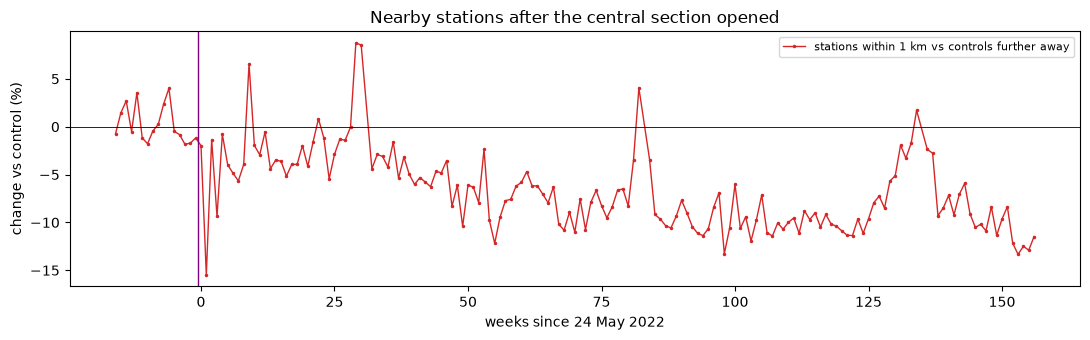

,nearby stations vs further controls (%)
weeks -16 to -1 (before),0.2
first 4 weeks,-7.2
weeks 4-12,-2.1
weeks 13-26,-3.0
weeks 27-52,-3.9
year 2,-8.3
year 3,-8.8


In [9]:
# Displacement: did stations within 1 km of the new stations lose traffic, relative to controls further away?
es_near = event_study(near, OPEN['Farringdon'], control=far)
plc_lo, plc_hi = plc_central.quantile(.025), plc_central.quantile(.975)
print(f"{len(near)} stations within 1 km: " + ', '.join(sorted(near)))
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(es_near.index, pct(es_near), 'C3.-', ms=3, lw=1, label='stations within 1 km vs controls further away')
ax.axvline(-.5, color='purple', lw=1); ax.axhline(0, color='black', lw=.6)
ax.set_xlabel('weeks since 24 May 2022'); ax.set_ylabel('change vs control (%)'); ax.legend(fontsize=8)
ax.set_title('Nearby stations after the central section opened'); plt.tight_layout(); plt.show()
nearby = pd.Series({k: round(pct(es_near.loc[a:b].mean()), 4) for k, (a, b) in PERIODS.items()}, name='nearby stations vs further controls (%)')
nearby.to_csv(B.RESULTS / 'elizabeth_line_daily_nearby.csv', index_label='period')
nearby.round(1).to_frame()

## Summary

* **The effect is immediate.** Footfall at Farringdon, Tottenham Court Road and Whitechapel was about
  **42% higher** than at comparable stations in the first four weeks after 24 May 2022, from a flat
  baseline (0.0% in the 16 weeks before). Bond Street, which opened five months later, rose about 22%.
* **It kept growing** with through services (Nov 2022) and the full timetable (May 2023): +65% in the
  second half of the first year, **+82% in year 2 and +88% in year 3** for the central three; about +34%
  to +44% at Bond Street.
* **It varies by station:** Farringdon (also a Thameslink interchange) +130% by year 3, Tottenham Court
  Road +95%, Whitechapel +47%, Bond Street +44%.
* **It is not chance:** no placebo set of control stations comes close (p = 0.0001 of 17,296 sets for the
  central three; p = 0.02, the smallest possible with 48 placebos, for Bond Street).
* **It agrees with the annual analysis:** 2019 to 2023 from daily weekday taps +73%, to 2025 +91%,
  against +84% and +94% from annual counts (which include weekends and a different count basis).
* **Part of it is passengers moving from nearby stations.** Stations within 1 km fell 2-9%
  relative to stations further away. Using only controls more than 1 km away lowers the year-3 effect
  from +88% to +82%; other changes to the control group or baseline move it by a few points.
* A data note: the Northern line Bank branch closure (Jan-May 2022) coincides with the baseline, so
  those stations are excluded from the control group; including them would inflate the placebo range.